# A campus drawn out, building by building: TAFE NSW Richmond

What if a campus's buildings are in no map data at all? OpenStreetMap has one building on this campus, the state's
footprints are not open, and the land title is a lot shared with the university next door. The buildings in
`data/geometry/` were drawn in [Plotlay](https://www.getplotlay.com) over NSW aerial imagery (CC BY 3.0 AU), each with
where its outline came from and how accurate it is likely to be. This notebook checks those, compares the outlines
with what Microsoft's machine learning found, checks Plotlay's roll-up to the site, and reads the sample facilities
tables in their own section at the end.

It reads only the files in `../data`. Accuracy depends on the imagery the outlines were drawn over.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*colormapping.*')
import pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
INK = '#1d4f91'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

## Sources and licence

NSW Imagery, (c) State of New South Wales (Spatial Services), CC BY 3.0 AU: the outlines were drawn over it. Two
outlines are Microsoft Global ML Building Footprints (CDLA Permissive 2.0) as they are. Nothing comes from
OpenStreetMap. `data/sample/` is sample data and is used only in the last section, labelled so.

In [2]:
b = pd.read_csv(f'{DATA}/buildings/buildings.csv')
shapes = gpd.read_file(f'{DATA}/geometry/campus_buildings.geojson').to_crs(7856)
site = gpd.read_file(f'{DATA}/geometry/campus_site.geojson').to_crs(7856)
roll = pd.read_csv(f'{DATA}/site/site_rollup.csv')
assert b.key.is_unique and set(b.key) == set(shapes.key)
print(len(b), 'buildings drawn;', f"campus {site.area.sum() / 10000:.1f} ha")
b.groupby(['outline_source', 'outline_accuracy_m']).size().rename('buildings').reset_index()

38 buildings drawn; campus 32.3 ha


,outline_source,outline_accuracy_m,buildings
0,"Microsoft footprint, picked as it is (a comple...",2.5,2
1,Traced over NSW Imagery (not in the Microsoft ...,0.5,5
2,"Traced over NSW Imagery, started from the Micr...",0.5,31


## The outlines against the table

Each shape's area worked out again from the geometry (MGA zone 56) against the footprint the table records.

largest difference 24.83% (the app squares what it draws); footprint in all 18,114 m²


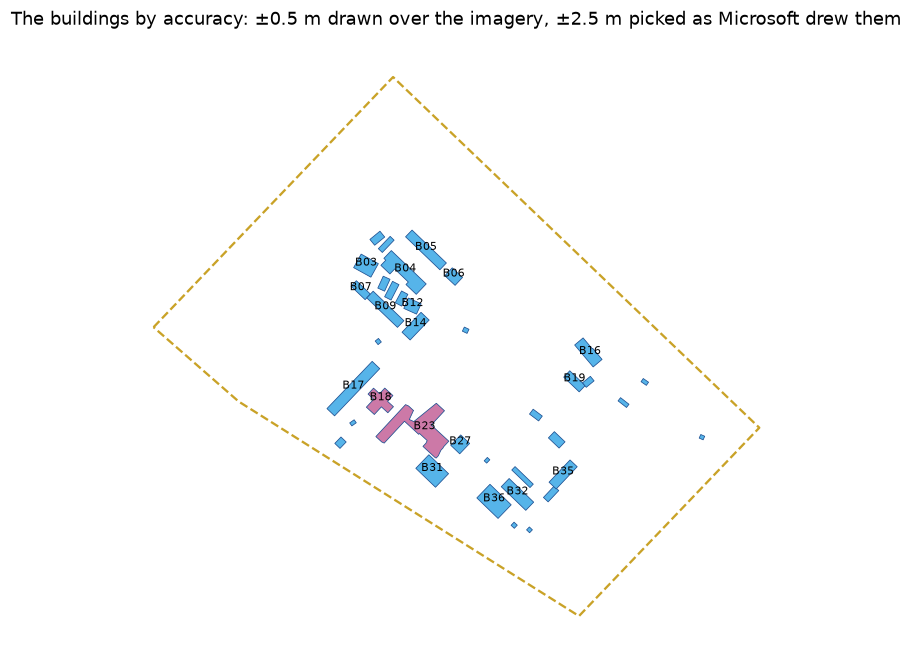

In [3]:
s = shapes.assign(area=shapes.area).merge(b[['key', 'footprint_m2', 'outline_accuracy_m']], on='key')
s['diff_pct'] = (s.area / s.footprint_m2 - 1) * 100
print(f"largest difference {s.diff_pct.abs().max():.2f}% (the app squares what it draws); footprint in all {s.area.sum():,.0f} m²")
fig, ax = plt.subplots(figsize=(9, 7))
site.boundary.plot(ax=ax, color='#c9a227', lw=1.5, ls='--')
cols = {0.5: '#56B4E9', 2.5: '#CC79A7'}
s.plot(ax=ax, color=[cols.get(a, '#E69F00') for a in s.outline_accuracy_m], edgecolor=INK, lw=.5)
for _, r in s.iterrows():
    if r.area > 300: ax.annotate(r.key, r.geometry.representative_point().coords[0], ha='center', fontsize=7)
ax.set_axis_off(); ax.set_title('The buildings by accuracy: ±0.5 m drawn over the imagery, ±2.5 m picked as Microsoft drew them'); plt.show()

## How far the machine-learned outlines were off

For the buildings Microsoft's footprints had, how far each outline moved when it was drawn onto the roof edges, and
how much the two overlapped.

31 buildings started from Microsoft's footprint: median offset 2.23 m, median overlap 0.67
5 buildings were in no open data at all


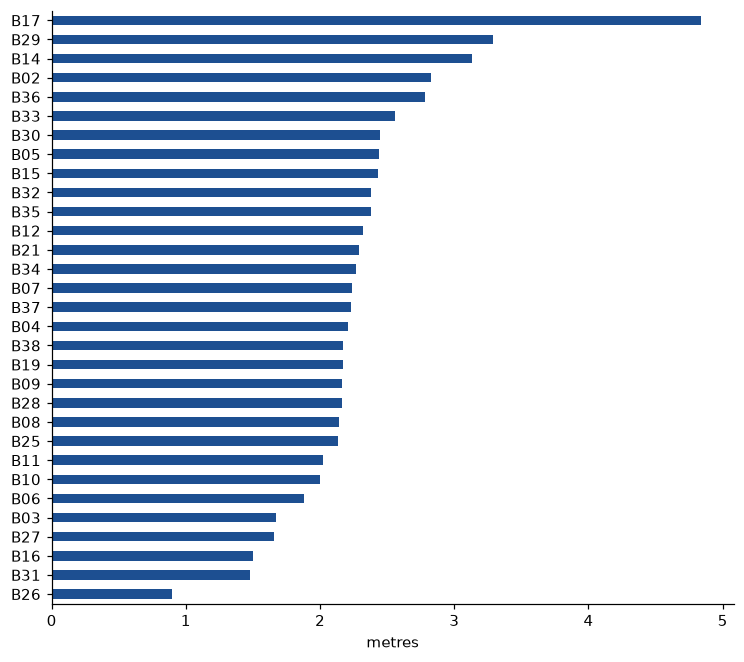

In [4]:
ms = b.dropna(subset=['microsoft_offset_m'])
print(f"{len(ms)} buildings started from Microsoft's footprint: median offset {ms.microsoft_offset_m.median():.2f} m, median overlap {ms.microsoft_overlap.median():.2f}")
print(f"{(b.in_microsoft_footprints == 'no').sum()} buildings were in no open data at all")
ax = ms.sort_values('microsoft_offset_m').plot.barh(x='key', y='microsoft_offset_m', color=INK, legend=False, figsize=(8, 7))
ax.set_xlabel('metres'); ax.set_ylabel(''); plt.show()

## The roll-up to the site

Plotlay counted the buildings inside the campus and added up their footprint; the same with a spatial join here.

In [5]:
inside = gpd.sjoin(shapes.set_geometry(shapes.representative_point()), site, predicate='within')
assert len(inside) == int(roll.buildings[0]) == len(b)
print(f"{len(inside)} of {len(b)} buildings inside the campus; Plotlay's roll-up: {int(roll.buildings[0])}, {roll.footprint_m2[0]:,.0f} m²")

38 of 38 buildings inside the campus; Plotlay's roll-up: 38, 18,109 m²


## Sample data: asset outcomes, building by building

Everything from here on reads `data/sample/`, which is sample data: the figures are not about TAFE NSW Richmond or
any real building. `data/sample/README.md` is the data dictionary. Nothing above uses these tables.

In [6]:
S = f'{DATA}/sample'
assets = pd.read_csv(f'{S}/assets.csv'); risk = pd.read_csv(f'{S}/asset_risk.csv'); wo = pd.read_csv(f'{S}/work_orders.csv')
pm = pd.read_csv(f'{S}/pm_compliance.csv'); esm = pd.read_csv(f'{S}/esm_register.csv'); cap = pd.read_csv(f'{S}/capital_works.csv'); summary = pd.read_csv(f'{S}/building_summary.csv')
for t in (assets, risk, wo, pm, esm, cap, summary): assert (t.data_status == 'Sample data').all()
open_wo = wo[~wo.status.isin(['Completed', 'Cancelled, missed'])]
print(f"Sample data: {len(assets)} assets, {(risk.risk_score >= 12).sum()} at high or extreme risk; {len(open_wo)} work orders open, {(wo.overdue == 'Yes').sum()} overdue;",
      f"planned maintenance on time {100 * pm.on_time.sum() / pm.scheduled.sum():.1f}%; safety measures overdue {(esm.status == 'Overdue').sum()} of {len(esm)}; backlog A${cap.estimate_aud.sum():,.0f}")

Sample data: 372 assets, 70 at high or extreme risk; 33 work orders open, 9 overdue; planned maintenance on time 88.1%; safety measures overdue 8 of 131; backlog A$3,054,000


In [7]:
pts = gpd.GeoDataFrame(assets.merge(risk[['asset_id', 'risk_score', 'risk_rating']], on='asset_id'), geometry=gpd.points_from_xy(assets.lng, assets.lat), crs=4326).to_crs(7856)
joined = gpd.sjoin(pts, shapes[['key', 'geometry']], how='left', predicate='within')
per = joined.groupby('key').agg(assets=('asset_id', 'count'), high_or_extreme=('risk_score', lambda x: (x >= 12).sum()))
check = per.merge(summary.set_index('key')[['assets', 'risk_high_or_extreme']].add_suffix('_table'), left_index=True, right_index=True)
assert (check.assets == check.assets_table).all() and (check.high_or_extreme == check.risk_high_or_extreme_table).all()
print('In the grounds:', joined.key.isna().sum(), 'assets; the roll-up into the buildings matches the summary table')
risk.pivot_table(index='likelihood_1to5', columns='consequence_1to5', values='asset_id', aggfunc='count', fill_value=0).sort_index(ascending=False)

In the grounds: 2 assets; the roll-up into the buildings matches the summary table


consequence_1to5,1,2,3,4,5
likelihood_1to5,,,,,
5,0,8,1,0,0
4,5,38,46,12,0
3,8,24,35,10,1
2,3,13,31,6,2
1,15,42,63,8,1


In [8]:
cap.pivot_table(index='building', columns='priority', values='estimate_aud', aggfunc='sum', fill_value=0, margins=True).sort_values('All', ascending=False).head(12)

priority,1 Within a year,2 In 2 to 3 years,3 In 4 to 5 years,4 In 6 to 10 years,All
building,,,,,
All,455000,2252000,288000,59000,3054000
B23,361000,266000,0,0,627000
B36,61000,338000,0,0,399000
B32,14000,267000,0,0,281000
B05,0,269000,0,0,269000
B17,0,268000,0,0,268000
B18,0,225000,0,0,225000
B14,2000,173000,0,0,175000
B35,0,0,108000,0,108000
